In [54]:
import sys 
sys.path.insert(0 ,'../src')

from utils.gpu import setup_gpu

setup_gpu()

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [55]:
import tensorflow as tf 
import numpy as np 
import PIL

In [56]:
base_model = tf.keras.applications.InceptionV3(
    include_top = False,
    weights = 'imagenet',
    pooling = 'avg',
    input_shape = (299,299,3)
)
base_model.trainable = False


In [57]:
img_path = "../data/Train/Glioma/images/gg (103).jpg"
img = PIL.Image.open(img_path).convert("RGB").resize((299,299))
x = np.array(img,dtype='float32')
x = np.expand_dims(x , axis=0)
x = tf.keras.applications.inception_v3.preprocess_input(x)

features = base_model(x , training=False)
print(features.shape)
print(features.device)
print(features.numpy()[0][:10])

(1, 2048)
/job:localhost/replica:0/task:0/device:GPU:0
[0.37451994 0.16930698 0.47302592 0.6651756  0.10038716 0.14207673
 0.36764476 0.35876256 0.05901448 0.12824838]


In [58]:
from pathlib import Path

In [59]:
DATA_DIR = Path("../data")

def print_tree(folder: Path , indent: str) :
    for sub in (subFolder for subFolder in folder.iterdir() if subFolder.is_dir()):
        n_files = sum(1 for file in sub.iterdir() if file.is_file())
        infos = f'--> ({n_files}) files' if n_files else ""
        print(f"{indent}{sub.name}{infos}")
        print_tree(sub , indent + "    ")
        
        
print_tree(DATA_DIR , "     ")

     Train
         Glioma
             images--> (1153) files
             labels--> (1153) files
         Meningioma
             images--> (1449) files
             labels--> (1449) files
         No Tumor
             images--> (711) files
             labels--> (711) files
         Pituitary
             images--> (1424) files
             labels--> (1424) files
     Val
         Glioma
             images--> (136) files
             labels--> (136) files
         Meningioma
             images--> (140) files
             labels--> (140) files
         No Tumor
             images--> (100) files
             labels--> (100) files
         Pituitary
             images--> (136) files
             labels--> (136) files


In [60]:
import pandas as pd

DATA_DIR = Path("../data")
IMG_EXTS = {".jpg", ".jpeg", ".png"}

rows = []
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        images = {f.stem for f in (class_dir / "images").iterdir() if f.suffix.lower() in IMG_EXTS}
        labels = {f.stem for f in (class_dir / "labels").iterdir() if f.suffix == ".txt"}

        rows.append({
            "split": split_dir.name,
            "class": class_dir.name,
            "images": len(images),
            "labels": len(labels),
            "pairs": len(images & labels),
            "images_without_label": len(images - labels),
            "labels_without_image": len(labels - images),
        })

pairing = pd.DataFrame(rows)

class_counts = pairing.groupby("class")["images"].sum()
class_names = pairing['class'].unique()
pairing

,split,class,images,labels,pairs,images_without_label,labels_without_image
0,Train,Glioma,1153,1153,1153,0,0
1,Train,Meningioma,1449,1449,1449,0,0
2,Train,No Tumor,711,711,711,0,0
3,Train,Pituitary,1424,1424,1424,0,0
4,Val,Glioma,136,136,136,0,0
5,Val,Meningioma,140,140,140,0,0
6,Val,No Tumor,100,100,98,2,2
7,Val,Pituitary,136,136,136,0,0


Text(0.5, 1.0, 'Images par classe (Train)')

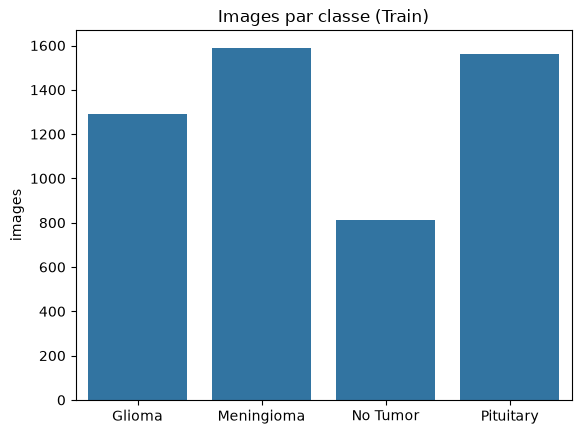

In [61]:
import seaborn as sns

sns.barplot(x=class_names , y=class_counts).set_title("Images par classe (Train)")

In [62]:
(pairing.groupby("class")["images"].sum() / pairing["images"].sum() * 100).round(1)


class
Glioma        24.6
Meningioma    30.3
No Tumor      15.5
Pituitary     29.7
Name: images, dtype: float64

In [63]:
from PIL import Image, UnidentifiedImageError

ALLOWED_EXTS = {".jpg", ".jpeg", ".png"}
valid, invalid = [], []

for file in DATA_DIR.rglob("*"):
    if not file.is_file() or file.parent.name != "images":
        continue                                   

    if file.suffix.lower() not in ALLOWED_EXTS:
        invalid.append((file, "extension"))
        continue

    try:
        with Image.open(file) as img:
            img.verify()                           
        with Image.open(file) as img:
            img.load()
        valid.append(file)
    except (UnidentifiedImageError, OSError) as e:
        invalid.append((file, f"corrompue: {e}"))

print(f"Valides : {len(valid)} | Invalides : {len(invalid)}")


Valides : 5249 | Invalides : 0


Text(0.5, 1.0, 'Images par classe')

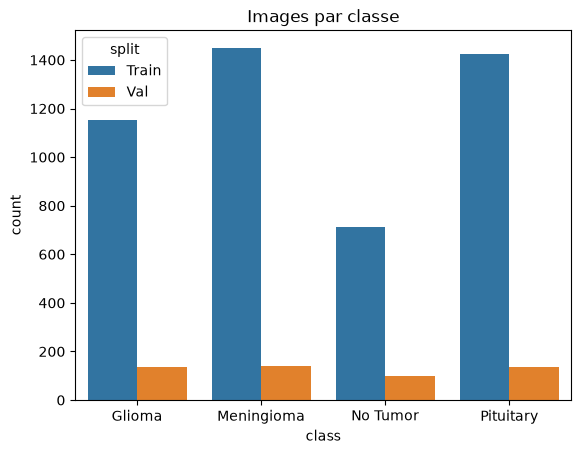

In [64]:
import pandas as pd

df = pd.DataFrame({
    "class": [f.parent.parent.name for f in valid],
    "split": [f.parents[2].name for f in valid],
    "path" : [f for f in valid]
})

sns.countplot(data=df, x="class", hue="split").set_title("Images par classe")


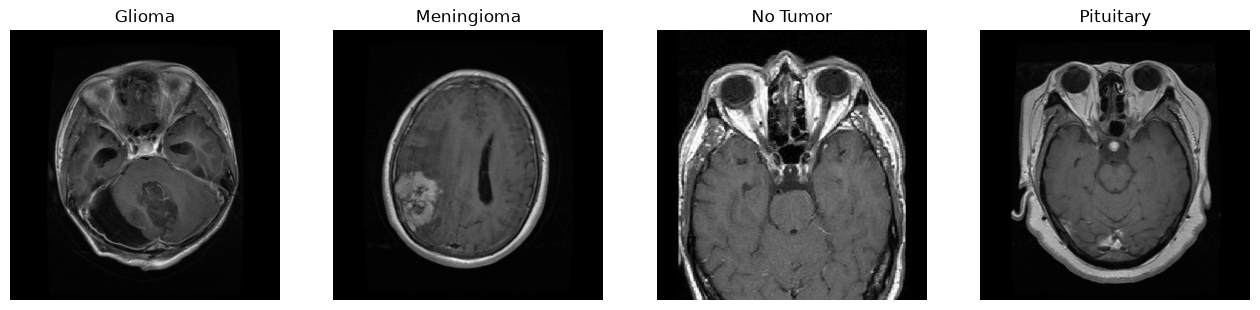

In [65]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax , cls in zip(axes , sorted(df['class'].unique())):
    sample = next(f for f in valid if f.parent.parent.name == cls)
    ax.imshow(Image.open(sample))
    ax.set_title(cls)
    ax.axis('off')
    
plt.show()
    
    

In [66]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["class"], random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["class"], random_state=42)

In [67]:
import shutil

OUT_DIR = Path("../processed/classification")

for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for path, cls in zip(split_df["path"], split_df["class"]):
        dest = OUT_DIR / split_name / cls
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, dest / Path(path).name)


In [68]:
train_df["set"] = "train"
val_df["set"]   = "val"
test_df["set"]  = "test"

split_df = pd.concat([train_df, val_df, test_df])

pd.crosstab(split_df["class"], split_df["set"], margins=True)


set,test,train,val,All
class,,,,
Glioma,194,902,193,1289
Meningioma,239,1112,238,1589
No Tumor,121,568,122,811
Pituitary,234,1092,234,1560
All,788,3674,787,5249


In [69]:
OUT_DIR = Path("../processed")

split_df[["path", "class", "set"]].to_csv(OUT_DIR / 'split.csv', index=False)